# Módulo 3 — Diferenciação e raízes unitárias

> **Controle bibliográfico — revisão de 21/11/2026 (M3S3).** Classificação: **parcial**.
> **Obra conferida:** MORETTIN, P. A.; TOLOI, C. M. C. *Análise de Séries Temporais: Modelos Lineares Univariados*, v. 1, 3ª ed., Blucher, 2018. Localização pertinente: **§2.6, pp. 35–36; §5.2, pp. 113–115; Apêndice B citado no sumário**.
> **Escopo:** Passeio aleatório e noções de integração; Apêndice B não acessível neste PDF de 150 páginas.
> A cópia enviada nesta revisão tem **150 páginas PDF** (até a p. impressa 131). Referências além desse limite, mesmo indicadas pelo sumário ou por edições integrais consultadas anteriormente, **não foram reconferidas nesta cópia**. Exemplos, demonstrações estendidas, gráficos e Python não são automaticamente atribuídos aos autores.


## Seção 3 — Processos integrados e raízes unitárias

**Estado:** versão didática para revisão. **Pré-requisitos:** processos estocásticos e estacionariedade (Módulo 1), tendências (Módulo 2) e operadores de diferença (Seções 1 e 2 deste módulo). **Integração computacional:** os experimentos em Python fazem parte da exposição e não constituem módulo separado.

**Fontes e alcance.** A discussão de raízes do polinômio autorregressivo e o modelo AR(1) estão fundamentados em Morettin e Toloi, *Análise de Séries Temporais: modelos lineares univariados*, v. 1, 3ª ed., Apêndice B, §B.1, p. 411 (página 430 do PDF fornecido); a transformação em diferenças também foi confrontada com o §B.2, pp. 412–413 (PDF 431–432), e a discussão introdutória de diferenciação, com §1.4, p. 6. Os exemplos numéricos, demonstrações detalhadas, simulações e discussões sobre a notação $I(d)$ são **complementações didáticas originais**, coerentes com esses fundamentos; não são transcrições do livro. No mapeamento do curso, consultar as aulas *Passeio aleatório*, *Aula 7 — ARMA, ARIMA e Testes de Estacionariedade* e *Aplicação de Diferenças*.

### Objetivos de aprendizagem

Ao concluir, você deverá: (i) distinguir persistência de choques e tendência determinística; (ii) interpretar o significado de uma raiz unitária; (iii) deduzir os momentos de um passeio aleatório; (iv) usar corretamente a notação $I(d)$; (v) explicar estacionariedade em processos AR(1) com atenção à inicialização; (vi) interpretar efeitos da diferenciação e da sobrediferenciação; (vii) implementar e comparar os modelos em Python.

### 1. Motivação: um choque passageiro ou permanente?

Compare dois modelos, ambos construídos a partir de perturbações $\varepsilon_t$ de média zero e variância constante $\sigma^2>0$:

$$
X_t=\alpha+\beta t+\varepsilon_t
$$

e

$$
Y_t=Y_{t-1}+\beta+\varepsilon_t,\qquad Y_0=\alpha.
$$

No primeiro caso, uma inovação alta em $t$ altera somente a observação daquele instante, se as inovações não forem autocorrelacionadas. No segundo, a inovação integra o nível a partir de $t$: suas consequências aparecem em todos os instantes seguintes. **Essa permanência** motiva o conceito de tendência estocástica e o estudo das raízes unitárias.

A similaridade entre as médias teóricas não basta para distinguir os processos:

$$
E[X_t]=E[Y_t]=\alpha+\beta t.
$$

Suas variâncias, sob inovações independentes, são, entretanto,

$$
\mathrm{Var}(X_t)=\sigma^2,\qquad
\mathrm{Var}(Y_t)=t\sigma^2.
$$

Uma mesma reta média pode, portanto, acompanhar dispersões de natureza muito diferente.

### 2. Modelo AR(1): raízes, persistência e condições de estacionariedade

Considere o modelo autorregressivo de primeira ordem

$$
Z_t=c+\phi Z_{t-1}+\varepsilon_t,
$$

em que $c$ e $\phi$ são números fixos; supomos, inicialmente, $\varepsilon_t$ com média zero, variância $\sigma^2$ e não correlacionado com o passado $Z_{t-1}$. Para construir uma solução *causal estacionária*, adotamos inovações de ruído branco em toda a reta temporal e $|\phi|<1$.

#### 2.1 A média em uma solução estacionária

Se a média for constante e finita, $E[Z_t]=\mu$, então

$$
\mu=c+\phi\mu,
$$

logo, para $\phi\neq1$,

$$
\boxed{\mu=\frac{c}{1-\phi}.}
$$

Essa identidade é uma **condição necessária** para uma solução estacionária com média finita; não demonstra, isoladamente, que ela exista.

#### 2.2 Variância e autocovariância

Subtraindo a média, obtemos

$$
Z_t-\mu=\phi(Z_{t-1}-\mu)+\varepsilon_t.
$$

Assumindo variância constante $v$ e que a inovação é não correlacionada com $Z_{t-1}$:

$$
\begin{aligned}
v&=\mathrm{Var}[\phi(Z_{t-1}-\mu)+\varepsilon_t]\\
 &=\phi^2v+\sigma^2.
\end{aligned}
$$

Portanto,

$$
\boxed{v=\frac{\sigma^2}{1-\phi^2},\qquad |\phi|<1.}
$$

Para defasagem $h\geq1$, ao multiplicar a equação centrada por $Z_{t-h}-\mu$ e tirar a esperança, usando a ortogonalidade da inovação em relação ao passado, encontramos

$$
\gamma(h)=\phi\gamma(h-1).
$$

Por indução, $\gamma(h)=\phi^h\gamma(0)$, isto é,

$$
\boxed{\gamma(h)=\frac{\sigma^2}{1-\phi^2}\phi^{|h|}.}
$$

**Cuidado de inicialização.** A recorrência simulada com $Z_0=0$ não tem necessariamente a distribuição estacionária desde o instante inicial. Para $|\phi|<1$, pode aproximá-la depois de um período de aquecimento (*burn-in*). Uma construção estacionária causal é

$$
Z_t=\mu+\sum_{j=0}^{\infty}\phi^j\varepsilon_{t-j},
$$

cuja convergência em média quadrática segue de $\sum_{j\geq0}\phi^{2j}<\infty$.

#### 2.3 O que acontece se $|\phi|\geq1$?

- $\phi=1$: ocorre o caso de **raiz unitária** e a equação se torna um passeio aleatório com possível deriva.
- $\phi>1$: partindo de uma condição inicial e de inovações não degeneradas, o processo causal para a frente apresenta comportamento explosivo típico.
- $\phi=-1$: também há raiz de módulo um, com alternância de sinal e ausência de uma solução causal estacionária usual sob inovações não degeneradas.
- $\phi<-1$: a solução causal para a frente tende a ser explosiva em módulo, com sinais alternados.

A discussão diz respeito à solução causal usual e à forma como o processo é gerado. A existência de soluções matemáticas não causais para certas equações autorregressivas exige hipóteses e interpretação diferentes.

### 3. Polinômio autorregressivo e a expressão “raiz unitária”

Use o operador de atraso $BZ_t=Z_{t-1}$, introduzido na Seção 1. Para $c=0$:

$$
Z_t-\phi Z_{t-1}=\varepsilon_t
\quad\Longleftrightarrow\quad
(1-\phi B)Z_t=\varepsilon_t.
$$

O polinômio autorregressivo é $\Phi(z)=1-\phi z$. Sua raiz, se $\phi\neq0$, é $z=1/\phi$. **A condição de causalidade estacionária do AR(1) é que essa raiz esteja fora do círculo unitário**, isto é, $|1/\phi|>1$, equivalente a $|\phi|<1$.

Quando $\phi=1$:

$$
\Phi(z)=1-z,
\qquad
\Phi(1)=0.
$$

Logo, **$z=1$ é uma raiz unitária do polinômio**. Não confunda a raiz $z=1/\phi$ com o próprio coeficiente $\phi$; no AR(1) particular, a condição $\phi=1$ produz justamente a raiz $z=1$.

### 4. O passeio aleatório: dedução completa dos momentos

Seja

$$
Z_t=Z_{t-1}+\varepsilon_t,\quad Z_0=0,
$$

com $\varepsilon_t$ independentes, $E[\varepsilon_t]=0$ e $\mathrm{Var}(\varepsilon_t)=\sigma^2$. Substituindo recursivamente:

$$
\begin{aligned}
Z_1&=\varepsilon_1,\\
Z_2&=\varepsilon_1+\varepsilon_2,\\
Z_3&=\varepsilon_1+\varepsilon_2+\varepsilon_3,\\
Z_t&=\sum_{k=1}^{t}\varepsilon_k.
\end{aligned}
$$

Pela linearidade da esperança:

$$
E[Z_t]=\sum_{k=1}^{t}E[\varepsilon_k]=0.
$$

Pela independência:

$$
\mathrm{Var}(Z_t)=\sum_{k=1}^{t}\mathrm{Var}(\varepsilon_k)=t\sigma^2.
$$

Para $1\leq s\leq t$:

$$
Z_t=\underbrace{\sum_{k=1}^{s}\varepsilon_k}_{Z_s}
+\sum_{k=s+1}^{t}\varepsilon_k.
$$

A segunda soma é independente de $Z_s$. Portanto,

$$
\begin{aligned}
\mathrm{Cov}(Z_s,Z_t)
&=\mathrm{Cov}\left(Z_s,Z_s+\sum_{k=s+1}^{t}\varepsilon_k\right)\\
&=\mathrm{Var}(Z_s)\\
&=s\sigma^2.
\end{aligned}
$$

Pela simetria da covariância, a fórmula geral é

$$
\boxed{\mathrm{Cov}(Z_s,Z_t)=\sigma^2\min(s,t).}
$$

**Exemplo numérico.** Se $\sigma^2=4$, então $\mathrm{Cov}(Z_2,Z_3)=8$ e $\mathrm{Cov}(Z_5,Z_6)=20$, embora os dois pares tenham defasagem 1. Além disso, $\mathrm{Var}(Z_3)=12$ e $\mathrm{Var}(Z_6)=24$. O processo não é fracamente estacionário por duas razões: a variância varia com o instante e a covariância não depende apenas da defasagem.

Com deriva $\delta$, isto é, $Z_t=Z_{t-1}+\delta+\varepsilon_t$, a média passa a ser $E[Z_t]=Z_0+\delta t$ (para $Z_0$ fixo), mas o crescimento da variância permanece $t\sigma^2$.

### 5. Integração de ordem $d$: o significado de $I(d)$

Um processo é denominado **integrado de ordem $d$**, escrito $Z_t\sim I(d)$, quando, nas condições usuais de modelagem, são necessárias $d$ diferenças ordinárias para obter um componente estocástico estacionário de ordem zero, e uma ordem menor não é suficiente. A convenção exige cuidado com termos determinísticos: uma série estacionária ao redor de uma tendência determinística não deve ser chamada automaticamente de $I(1)$ só porque sua primeira diferença é estacionária.

- **$I(0)$:** processo estacionário de segunda ordem sob as hipóteses adotadas, sem raiz unitária na parte autorregressiva e usualmente de memória curta no contexto ARMA.
- **$I(1)$:** uma primeira diferença é $I(0)$, enquanto o componente estocástico em níveis não é $I(0)$; o passeio aleatório é o exemplo fundamental.
- **$I(2)$:** são necessárias duas diferenças para chegar a um processo $I(0)$, sem que uma única diferença seja suficiente.

Para o passeio aleatório:

$$
(1-B)Z_t=\varepsilon_t.
$$

Como $\varepsilon_t$ é ruído branco de variância finita, $Z_t$ é um exemplo típico de $I(1)$.

**Exemplo $I(2)$, construído didaticamente.** Defina $W_t=W_{t-1}+\varepsilon_t$ e $Z_t=Z_{t-1}+W_t$, com condições iniciais fixas. Então

$$
\Delta Z_t=W_t,
\qquad
\Delta^2 Z_t=\Delta W_t=\varepsilon_t.
$$

Assim, a segunda diferença recupera o ruído branco; a primeira permanece um passeio aleatório. Esse é um exemplo de mecanismo $I(2)$.

**Cuidado:** a notação $I(d)$ identifica estrutura estocástica sob condições de existência e regularidade. Ter uma série que *parece suave* não constitui prova de integração, e um resultado de teste estatístico também não estabelece a ordem com certeza absoluta.

### 6. Diferenciar não é a mesma coisa que retirar uma tendência

Considere, novamente, $X_t=\alpha+\beta t+\varepsilon_t$, onde $\varepsilon_t$ é ruído branco. Há dois procedimentos distintos:

**Retirar a tendência conhecida:**

$$
X_t-(\alpha+\beta t)=\varepsilon_t.
$$

**Diferenciar:**

$$
\Delta X_t=\beta+\varepsilon_t-\varepsilon_{t-1}.
$$

Sob ruído branco,

$$
\mathrm{Var}(\Delta X_t)=2\sigma^2
$$

e a covariância na defasagem 1 é

$$
\mathrm{Cov}(\Delta X_t,\Delta X_{t-1})=-\sigma^2.
$$

Assim, a autocorrelação de primeira ordem vale $-1/2$. A diferenciação criou dependência linear negativa mesmo que os erros originais não fossem correlacionados. Essa observação explica a **sobrediferenciação**: diferenciar uma série que já era estacionária pode criar estrutura desnecessária e complicar a modelagem. Uma demonstração de que *qualquer* diferença desse tipo é inadequada para todo objetivo exigiria mais hipóteses; a afirmação aqui diz respeito ao risco estatístico do procedimento.

### 7. Python integrado — três regimes do AR(1)

No experimento a seguir, a função `ar1` implementa recursivamente a equação do modelo. Em `np.random.default_rng`, a semente fixa torna o experimento reproduzível. Para fins de comparação visual, utilizamos **as mesmas inovações** nos três processos; isso não os transforma em uma única série nem altera suas propriedades marginais.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261115)
n = 240
innov = rng.normal(loc=0, scale=1, size=n)

def ar1(phi, eps, initial=0.0):
    z = np.empty(len(eps) + 1)
    z[0] = initial
    for t in range(1, len(z)):
        z[t] = phi * z[t - 1] + eps[t - 1]
    return z[1:]

phis = [0.65, 1.0, 1.02]
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

for ax, phi in zip(axes, phis):
    serie = ar1(phi, innov)
    ax.plot(np.arange(1, n + 1), serie)
    ax.set_title(f"AR(1): phi = {phi}")
    ax.set_ylabel("Valor")
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Instante t")
fig.tight_layout()
plt.show()

**Leitura do gráfico:** o modelo com $\phi=0{,}65$ tende a reverter ao seu nível de equilíbrio, após o efeito transitório da inicialização; $\phi=1$ acumula choques; $\phi=1{,}02$ pode apresentar amplificação expressiva do nível. O sinal e a intensidade de cada trajetória dependem das inovações sorteadas. **Um gráfico isolado não comprova** estacionariedade nem a existência de uma raiz unitária.

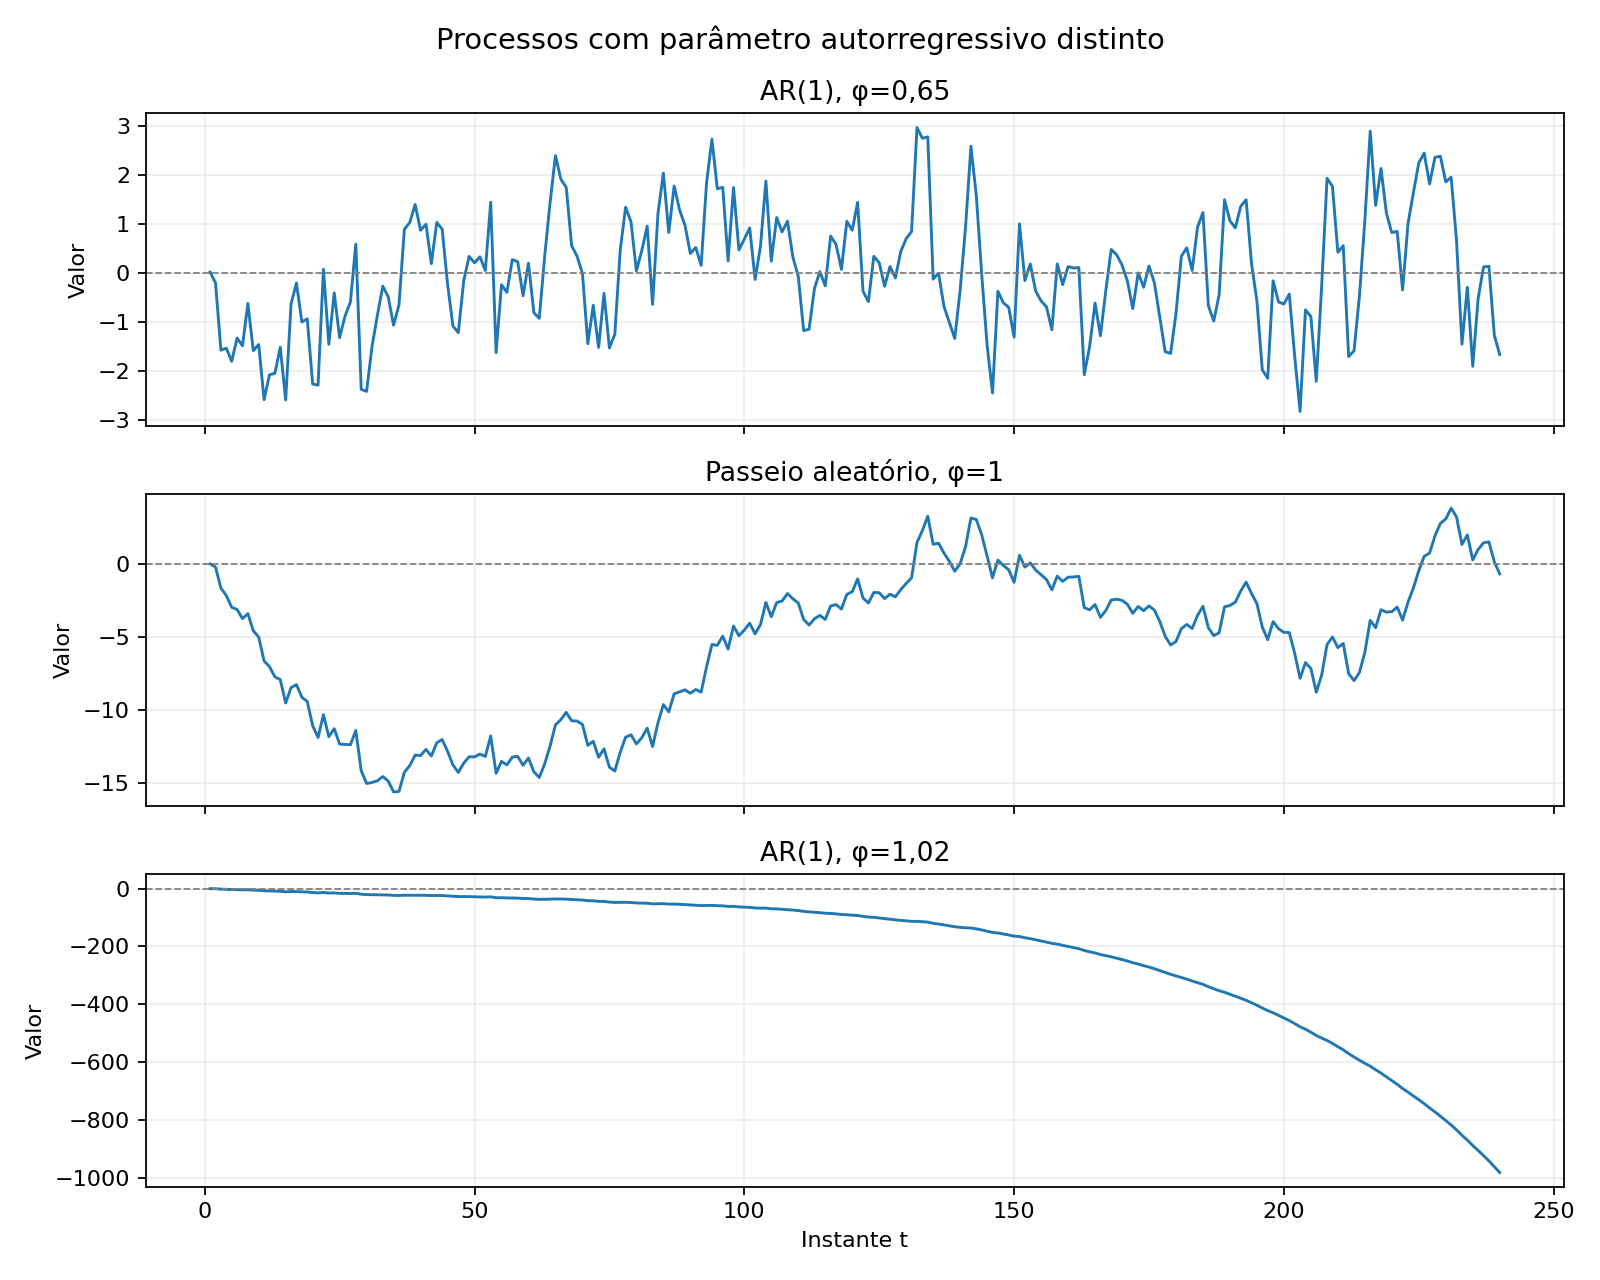

*Figura 1 — Séries sintéticas com diferentes coeficientes $\phi$. Imagem gerada pelo script Python desta seção.*

#### 7.1 Simulação de muitas trajetórias: verificar a fórmula da variância

In [ ]:
m = 2500
n_instantes = 65
ruidos = rng.normal(0, 1, size=(m, n_instantes))
trajetorias = np.cumsum(ruidos, axis=1)

variancias = trajetorias.var(axis=0, ddof=0)
variancia_teorica = np.arange(1, n_instantes + 1)

plt.figure(figsize=(10, 4))
plt.plot(variancias, label="Variância entre trajetórias")
plt.plot(variancia_teorica, "--", label="t (teoria)")
plt.xlabel("Instante (índice iniciado em zero no gráfico)")
plt.ylabel("Variância")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

`np.cumsum(..., axis=1)` calcula somas acumuladas **ao longo do tempo em cada linha**. `var(axis=0)` estima a variância **entre realizações em cada coluna temporal**. Com `ddof=0`, usamos o denominador $M$ da variância empírica, não o estimador amostral corrigido de denominador $M-1$. Esperamos proximidade, não igualdade exata, com a curva teórica.

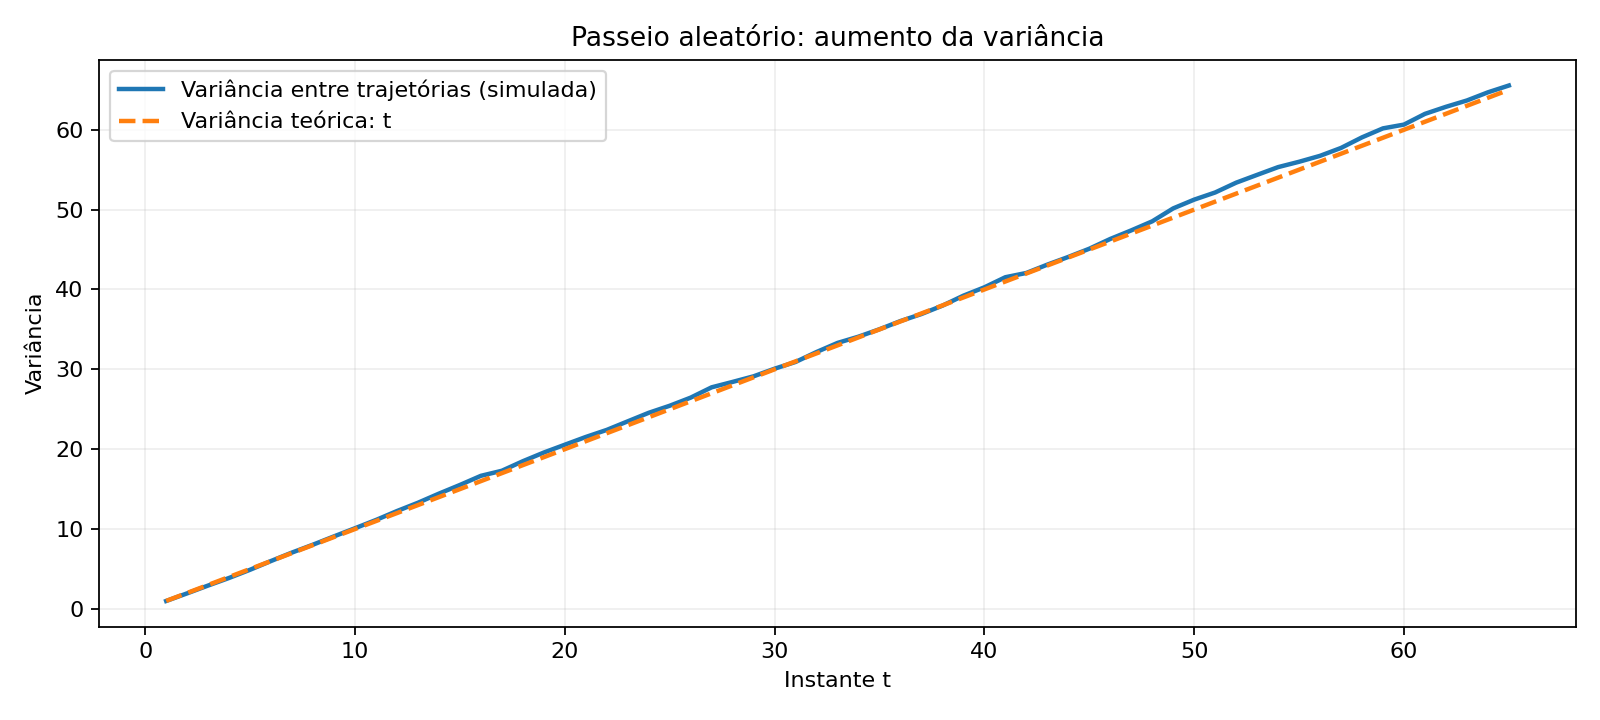

*Figura 2 — Comparação entre a variância entre 2.500 trajetórias e $\mathrm{Var}(Z_t)=t$ para inovações de variância 1. A simulação ilustra a teoria; não constitui demonstração.*

### 8. Limitações e decisões metodológicas

Uma raiz unitária pode ser difícil de distinguir de um coeficiente muito próximo de 1 em amostras curtas. Quebras estruturais, tendências determinísticas omitidas, sazonalidade e erros autocorrelacionados podem tornar gráficos e testes enganosos. Não se recomenda diferenciar automaticamente toda série com tendência visual. Também não se deve confundir uma raiz sazonal (por exemplo, em $1-B^s$) com a raiz ordinária $z=1$ sem considerar a fatoração do polinômio sazonal.

### 9. Exercícios para estudo autônomo

1. **Conceitual:** explique por que o AR(1) com $|\phi|<1$ pode ser estacionário mesmo que duas observações consecutivas sejam correlacionadas.
2. **Cálculo:** para $\phi=0{,}5$ e $\sigma^2=3$, determine a variância estacionária e $\gamma(2)$.
3. **Demonstração:** partindo de $Z_t=Z_{t-1}+\varepsilon_t$, prove $\mathrm{Cov}(Z_s,Z_t)=\sigma^2\min(s,t)$ para $s,t\geq1$.
4. **Operadores:** expanda $(1-B)^2Z_t$ e explique o motivo de um processo $I(2)$ precisar de duas diferenças.
5. **Programação guiada:** modifique o exemplo AR(1) para $\phi=-0{,}7$ e descreva o padrão alternante. Antes de implementar, escreva pseudocódigo para a atualização recursiva.
6. **Aprofundamento:** mostre que a primeira diferença de um ruído branco tem autocorrelação de lag 1 igual a $-1/2$, quando $\sigma^2>0$.

**Orientações selecionadas:** no exercício 2, use $\gamma(0)=\sigma^2/(1-\phi^2)$ e $\gamma(2)=\phi^2\gamma(0)$; no exercício 5, compare os sinais de valores adjacentes, sem inferir estacionariedade exclusivamente do gráfico.

### 10. Síntese e referências

A ordem de integração descreve quantas diferenças são necessárias para obter um componente estocástico estacionário sob as condições apropriadas. Uma raiz unitária fornece uma explicação algébrica para o acúmulo de inovações. O passeio aleatório difere fundamentalmente de uma série estacionária ao redor de tendência determinística: seus choques têm efeito duradouro e sua variância cresce com o tempo.

- MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed., v. 1. São Paulo: Blucher, 2018. Apêndice B, especialmente §§B.1–B.2, pp. 411–413; §1.4, p. 6. **Trechos consultados visualmente.**
- *Mapeamento de conteúdos para iniciação científica: séries temporais*, arquivo local `mapeamento-conteudos-series-temporais.md`, registros sobre passeio aleatório, diferenciação, ARIMA e testes.
- Complementações originais deste capítulo: exemplos $I(2)$, discussões sobre inicialização e sobrediferenciação, implementação e exercícios.

**Continuidade:** a Seção 4 explicará como testes estatísticos investigam uma hipótese de raiz unitária, respeitando suas suposições e limitações.